# Credit Card Fraud Detection
**Classification, evaluation beyond accuracy, threshold tuning, and monitoring**

This notebook builds and evaluates fraud detection models on real, highly imbalanced transaction data.

**Dataset:** Kaggle "Credit Card Fraud Detection": https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
Download `creditcard.csv` from Kaggle and place it in the `data/` folder (the dataset is not stored in this repository).

**Steps**
1. Load and explore the data
2. Engineer features
3. Split by time (train on the past, test on the future)
4. Show why accuracy is misleading
5. Train three models: logistic regression, gradient boosting, and an unsupervised Isolation Forest
6. Evaluate with precision, recall, PR-AUC, and false positive rate, and tune decision thresholds
7. Build a monitoring view of alerts over time
8. Document the results

In [1]:
# Run this once if any library is missing:
# %pip install -r requirements.txt

import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = "data/creditcard.csv"   # download from Kaggle (see README)
RESULTS_DIR = "results"
TARGET_PRECISION = 0.90              # used for a "few false alarms" threshold
os.makedirs(RESULTS_DIR, exist_ok=True)
pd.set_option("display.max_columns", 50)

## 1. Load and explore the data
Each row is a transaction. `V1` to `V28` are anonymized features, `Amount` is the transaction amount,
`Time` is seconds since the first transaction, and `Class` is 1 for fraud.

In [2]:
df = pd.read_csv(DATA_PATH).sort_values("Time").reset_index(drop=True)
print(f"{len(df):,} transactions | {int(df['Class'].sum()):,} fraud cases | fraud rate {df['Class'].mean():.3%}")
df.groupby("Class")["Amount"].describe()

284,807 transactions | 492 fraud cases | fraud rate 0.173%


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


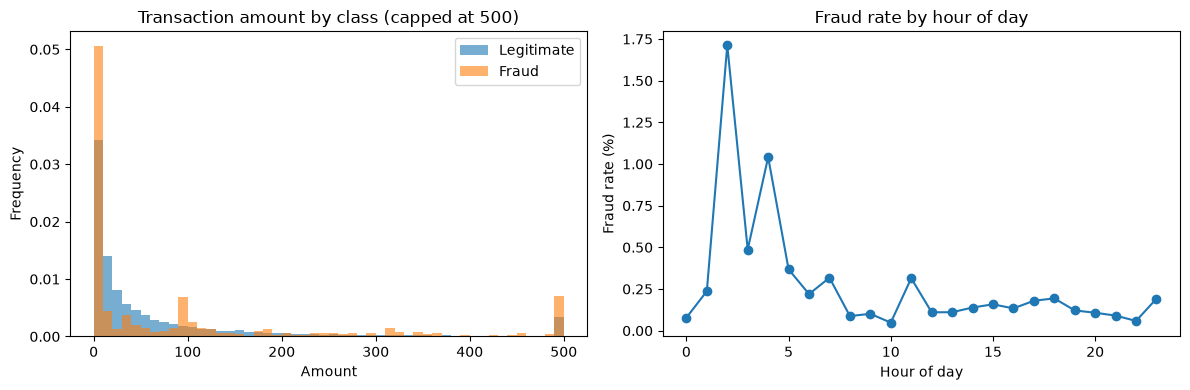

In [3]:
df["hour"] = (df["Time"] // 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.loc[df["Class"] == 0, "Amount"].clip(upper=500).plot.hist(bins=50, ax=axes[0], alpha=0.6, density=True, label="Legitimate")
df.loc[df["Class"] == 1, "Amount"].clip(upper=500).plot.hist(bins=50, ax=axes[0], alpha=0.6, density=True, label="Fraud")
axes[0].set_title("Transaction amount by class (capped at 500)")
axes[0].set_xlabel("Amount")
axes[0].legend()

df.groupby("hour")["Class"].mean().mul(100).plot(ax=axes[1], marker="o")
axes[1].set_title("Fraud rate by hour of day")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()

## 2. Feature engineering
Transaction amounts are heavily skewed, so we use a log scale. Hour of day captures time-of-day patterns.

In [4]:
df["log_amount"] = np.log1p(df["Amount"])
FEATURES = [c for c in df.columns if c.startswith("V")] + ["log_amount", "hour"]
print(len(FEATURES), "features:", FEATURES[:3], "...", FEATURES[-2:])

30 features: ['V1', 'V2', 'V3'] ... ['log_amount', 'hour']


## 3. Time-based split
A real fraud model always predicts on **future** transactions, so we split by time instead of at random:
the earliest 60% for training, the next 20% for choosing thresholds (validation), and the latest 20% for the final test.

In [5]:
n = len(df)
train, val, test = df.iloc[: int(n * 0.6)], df.iloc[int(n * 0.6): int(n * 0.8)], df.iloc[int(n * 0.8):]
Xtr, ytr = train[FEATURES].values, train["Class"].values
Xva, yva = val[FEATURES].values, val["Class"].values
Xte, yte = test[FEATURES].values, test["Class"].values

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:>10}: {len(part):,} rows, fraud rate {part['Class'].mean():.3%}")

     train: 170,884 rows, fraud rate 0.211%
validation: 56,961 rows, fraud rate 0.100%
      test: 56,962 rows, fraud rate 0.132%


## 4. Why accuracy is misleading
With fraud this rare, a model that never flags anything looks almost perfect on accuracy.

In [6]:
flag_nothing_accuracy = 1 - yte.mean()
print(f"A model that never flags fraud scores {flag_nothing_accuracy:.2%} accuracy on the test period, and catches zero fraud.")

A model that never flags fraud scores 99.87% accuracy on the test period, and catches zero fraud.


## 5. Train three models
- **Logistic regression:** a simple, explainable baseline, with class weights to handle the imbalance
- **Gradient boosting:** scikit-learn's histogram-based gradient boosting, with class weights
- **Isolation Forest:** unsupervised anomaly detection that never sees the fraud labels

In [7]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
logreg.fit(Xtr, ytr)

gb_name = "Gradient Boosting"
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=42)
gb.fit(Xtr, ytr)

iso = IsolationForest(n_estimators=300, random_state=42).fit(Xtr)   # never sees the labels

scorers = {
    "Logistic Regression": lambda X: logreg.predict_proba(X)[:, 1],
    gb_name: lambda X: gb.predict_proba(X)[:, 1],
    "Isolation Forest (unsupervised)": lambda X: -iso.decision_function(X),
}
print("Trained:", ", ".join(scorers))

Trained: Logistic Regression, Gradient Boosting, Isolation Forest (unsupervised)


## 6. Evaluation beyond accuracy, with threshold tuning
Thresholds are chosen on the **validation** set only, then applied to the test set:
- **Max F1:** the best balance of precision and recall
- **Target precision:** keeps false alarms low for the analysts who review alerts

Metrics: PR-AUC, ROC-AUC, precision, recall, F1, false positive rate, and alerts per 10,000 transactions.

In [8]:
def best_f1_threshold(y, scores):
    p, r, t = precision_recall_curve(y, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.nanargmax(f1))])

def threshold_for_precision(y, scores, target):
    p, r, t = precision_recall_curve(y, scores)
    ok = np.where(p[:-1] >= target)[0]
    return float(t[ok[0]]) if len(ok) else None   # lowest qualifying threshold catches the most fraud

def evaluate(name, rule, y, scores, thr):
    pred = (scores >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "model": name, "threshold_rule": rule, "threshold": round(thr, 4),
        "pr_auc": round(average_precision_score(y, scores), 4),
        "roc_auc": round(roc_auc_score(y, scores), 4),
        "precision": round(tp / (tp + fp), 4) if tp + fp else 0.0,
        "recall": round(tp / (tp + fn), 4) if tp + fn else 0.0,
        "f1": round(f1_score(y, pred, zero_division=0), 4),
        "false_positive_rate": round(fp / (fp + tn), 6) if fp + tn else 0.0,
        "accuracy": round(accuracy_score(y, pred), 4),
        "alerts_per_10k": round(pred.mean() * 10000, 1),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }

In [9]:
results, test_scores = [], {}
for name, score in scorers.items():
    s_val, s_test = score(Xva), score(Xte)
    test_scores[name] = s_test
    results.append(evaluate(name, "max F1 on validation", yte, s_test, best_f1_threshold(yva, s_val)))
    thr = threshold_for_precision(yva, s_val, TARGET_PRECISION)
    if thr is not None:
        results.append(evaluate(name, f"precision >= {TARGET_PRECISION:.0%} on validation", yte, s_test, thr))

res = pd.DataFrame(results)
best = res.sort_values("pr_auc", ascending=False).iloc[0]
res

,model,threshold_rule,threshold,pr_auc,roc_auc,precision,recall,f1,false_positive_rate,accuracy,alerts_per_10k,tp,fp,fn,tn
0,Logistic Regression,max F1 on validation,1.0000,0.7484,0.9833,0.9615,0.6667,0.7874,0.000035,0.9995,9.1,50,2,25,56885
1,Logistic Regression,precision >= 90% on validation,1.0000,0.7484,0.9833,0.9273,0.6800,0.7846,0.000070,0.9995,9.7,51,4,24,56883
2,Gradient Boosting,max F1 on validation,0.9748,0.7237,0.9591,0.9091,0.6667,0.7692,0.000088,0.9995,9.7,50,5,25,56882
3,Gradient Boosting,precision >= 90% on validation,0.9511,0.7237,0.9591,0.8621,0.6667,0.7519,0.000141,0.9994,10.2,50,8,25,56879
4,Isolation Forest (unsupervised),max F1 on validation,0.0958,0.0439,0.9520,0.0628,0.3067,0.1043,0.006029,0.9931,64.3,23,343,52,56544


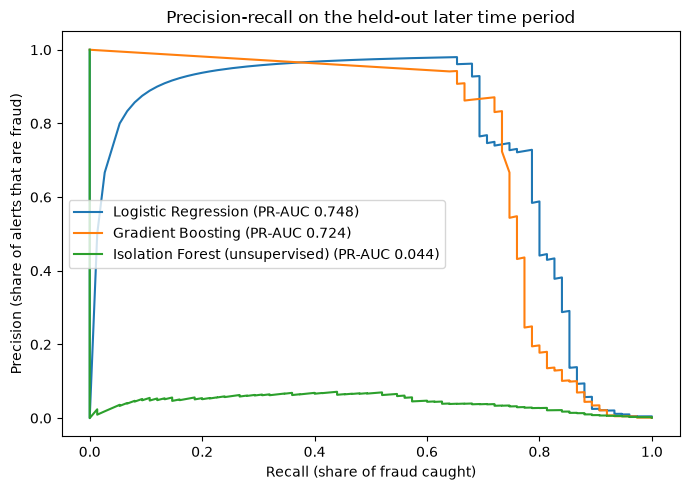

In [10]:
plt.figure(figsize=(7, 5))
for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(yte, s)
    plt.plot(r, p, label=f"{name} (PR-AUC {average_precision_score(yte, s):.3f})")
plt.xlabel("Recall (share of fraud caught)")
plt.ylabel("Precision (share of alerts that are fraud)")
plt.title("Precision-recall on the held-out later time period")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/pr_curves.png", dpi=150)
plt.show()

## 7. Monitoring view
How many alerts the best model raises each hour, compared with confirmed fraud. This is the kind of chart
a team can watch without an analyst in the loop.

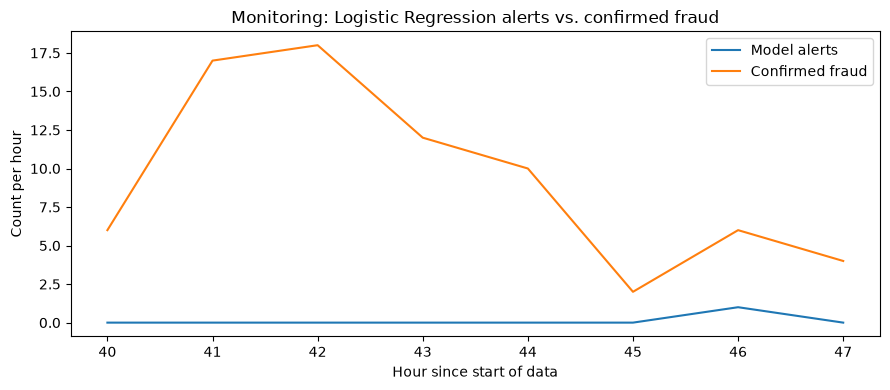

In [11]:
t = test.copy()
t["alert"] = (test_scores[best["model"]] >= best["threshold"]).astype(int)
t["hour_index"] = (t["Time"] // 3600).astype(int)
hourly = t.groupby("hour_index")[["alert", "Class"]].sum()

plt.figure(figsize=(9, 4))
plt.plot(hourly.index, hourly["alert"], label="Model alerts")
plt.plot(hourly.index, hourly["Class"], label="Confirmed fraud")
plt.xlabel("Hour since start of data")
plt.ylabel("Count per hour")
plt.title(f"Monitoring: {best['model']} alerts vs. confirmed fraud")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/monitoring_hourly_alerts.png", dpi=150)
plt.show()

## 8. Which features matter most?
Logistic regression coefficients on standardized features show which signals push a transaction toward "fraud."

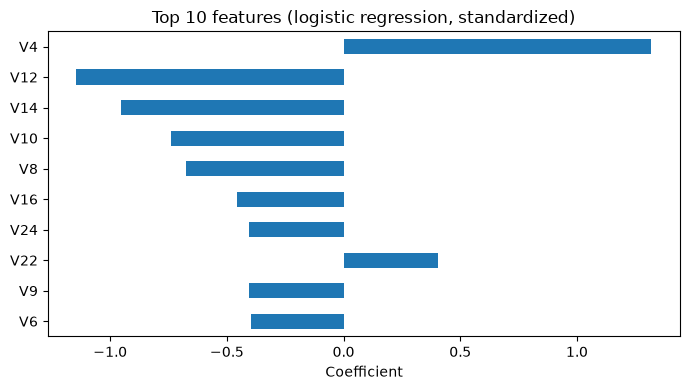

V4     1.318382
V12   -1.144284
V14   -0.951697
V10   -0.737496
V8    -0.676679
V16   -0.458008
V24   -0.403721
V22    0.403601
V9    -0.403159
V6    -0.395498
dtype: float64

In [12]:
coefs = pd.Series(logreg.named_steps["logisticregression"].coef_[0], index=FEATURES)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
top.plot.barh(figsize=(7, 4))
plt.gca().invert_yaxis()
plt.title("Top 10 features (logistic regression, standardized)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()
top

## 9. Document the results
Writes `results/results.md` (data, method, metrics, findings) and `results/results.json`, then prints a short summary.

In [13]:
def md_table(frame):
    cols = list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, row in frame.iterrows():
        lines.append("| " + " | ".join(str(row[c]) for c in cols) + " |")
    return "\n".join(lines)

table = md_table(res[["model", "threshold_rule", "pr_auc", "roc_auc", "precision", "recall",
                      "false_positive_rate", "alerts_per_10k", "accuracy"]])
with open(f"{RESULTS_DIR}/results.md", "w") as f:
    f.write("# Credit Card Fraud Detection: Results\n\n")
    f.write(f"**Data:** {n:,} transactions, {int(df['Class'].sum()):,} fraud cases ({df['Class'].mean():.3%}).\n\n")
    f.write("**Method:** time-based split (60% train, 20% validation for threshold tuning, 20% test on the latest "
            "transactions). Features: V1 to V28, log transaction amount, and hour of day. Thresholds chosen on validation only.\n\n")
    f.write(f"**Why not accuracy:** a model that flags nothing scores {flag_nothing_accuracy:.2%} accuracy while catching zero fraud.\n\n")
    f.write("## Test-period metrics\n\n" + table + "\n\n")
    f.write(f"**Best model by PR-AUC:** {best['model']} ({best['threshold_rule']}): PR-AUC {best['pr_auc']}, "
            f"precision {best['precision']:.0%}, recall {best['recall']:.0%}, false positive rate {best['false_positive_rate']:.3%}.\n")
res.to_json(f"{RESULTS_DIR}/results.json", orient="records", indent=2)
print(f"Saved results.md, results.json, pr_curves.png, monitoring_hourly_alerts.png to {RESULTS_DIR}/")

print("\nSummary:")
print(json.dumps({"rows": n, "fraud_cases": int(df["Class"].sum()),
                  "fraud_rate": round(float(df["Class"].mean()), 5),
                  "flag_nothing_accuracy": round(float(flag_nothing_accuracy), 4),
                  "best": best.to_dict()}, default=str, indent=2))

Saved results.md, results.json, pr_curves.png, monitoring_hourly_alerts.png to results/

Summary:
{
  "rows": 284807,
  "fraud_cases": 492,
  "fraud_rate": 0.00173,
  "flag_nothing_accuracy": 0.9987,
  "best": {
    "model": "Logistic Regression",
    "threshold_rule": "max F1 on validation",
    "threshold": 1.0,
    "pr_auc": 0.7484,
    "roc_auc": 0.9833,
    "precision": 0.9615,
    "recall": 0.6667,
    "f1": 0.7874,
    "false_positive_rate": 3.5e-05,
    "accuracy": 0.9995,
    "alerts_per_10k": 9.1,
    "tp": 50,
    "fp": 2,
    "fn": 25,
    "tn": 56885
  }
}


## Takeaways and next steps
- **Time-based evaluation matters.** Fraud models predict the future, and fraud patterns shift; a random split would leak future patterns into training.
- **Accuracy is the wrong metric here.** With fraud this rare, PR-AUC, precision, recall, and false positive rate show real performance.
- **Thresholds are a business decision.** The right cutoff balances missed fraud against analyst time spent on false alarms.
- **Labels are valuable.** Comparing supervised models with the unsupervised Isolation Forest shows how much confirmed cases improve detection.

**Next steps:** cost-based thresholds (missed fraud vs. review cost), richer behavioral features, and drift monitoring as fraud patterns change.